# Walkthrough: smart-home appliance anomaly detection (validated on fridges and freezers)

This notebook reads the saved outputs of `python -m smart_energy.experiments` (in `results/` and `reports/figures/`) and
walks through them in order. It needs no raw data. To reproduce the numbers, download REFIT (see `data/README.md`), run
`python scripts/ingest_refit.py data/raw/refit data/interim`, then `python -m smart_energy.experiments` (about 45 minutes).

The full step-by-step code (every function visible) is in the separate end-to-end learning notebook.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
R, FIG = Path("../results"), Path("../reports/figures")
load = lambda n: json.loads((R / n).read_text())
pd.set_option("display.width", 160)

## 1. Data quality

In [2]:
q = load("data_quality.json")
print(f"{q['houses']} homes, {q['raw_rows']:,} raw readings, mean {q['days_mean']:.0f} days per home")
print(f"minutes with readings: {q['minute_coverage_mean']:.1%} on average (lowest home {q['minute_coverage_min']:.1%})")
print(f"impossible appliance readings (> 4000 W) removed: {q['impossible_readings_removed']:,} ({q['impossible_share_of_appliance_readings']:.4%})")
print(f"annotations: {q['annotation_rows']} rows; duplicates {q['annotation_duplicates']}; end before start {len(q['annotation_end_before_start'])}")
print("'sensor stuck' windows shared across homes:", q["shared_stuck_days"])
display(pd.DataFrame(q["outage_reading_rates"]).set_index("house").T)
print(f"scope: {q['cold_channels']} cold appliances in {q['cold_houses']} homes; {q['fault_events_scoreable']} scoreable anomalies; "
      f"anomaly hours = {q['fault_hour_rate']:.2%} of scored hours")
display(pd.read_csv(R / "data_quality_channels.csv").set_index("appliance").round(2))

20 homes, 129,223,484 raw readings, mean 544 days per home
minutes with readings: 88.0% on average (lowest home 75.4%)
impossible appliance readings (> 4000 W) removed: 44,149 (0.0038%)
annotations: 337 rows; duplicates 1; end before start 2
'sensor stuck' windows shared across homes: {'2014-08-01': 11, '2014-08-30': 6, '2014-09-07': 5, '2014-02-28': 2}


house,1,2,3,4,7,8,10,11,17,19,20
readings_per_min_outage,0.98,0.98,0.98,0.98,0.98,0.98,0.98,0.98,0.98,0.97,0.98
readings_per_min_week_before,12.53,13.04,14.92,14.17,13.34,12.62,13.16,15.10,12.78,14.81,12.59


scope: 32 cold appliances in 19 homes; 243 scoreable anomalies; anomaly hours = 1.73% of scored hours


,type,threshold_w,on_power_w,duty,starts_per_day,coverage
appliance,,,,,,
H1-Freezer_1,freezer,23.00,46.75,0.32,25.95,0.87
H1-Freezer_2,freezer,34.67,70.20,0.40,21.58,0.87
H1-Fridge,fridge,37.31,74.95,0.18,11.13,0.87
H10-ChestFreezer,freezer,38.45,70.57,0.58,19.43,0.89
H10-Fridge-Freezer,fridge_freezer,48.60,97.67,0.13,18.03,0.89
H11-Fridge,fridge,17.83,35.69,0.13,10.28,0.89
H11-Fridge-Freezer,fridge_freezer,39.65,82.42,0.22,11.20,0.89
H12-Fridge-Freezer,fridge_freezer,43.14,91.75,0.31,12.15,0.93
H15-Fridge-Freezer,fridge_freezer,36.60,77.14,0.32,18.72,0.86


The 1 Aug 2014 'sensor stuck' window appears in 11 homes at once and the reporting rate drops ~13x in all of them: a
data-collection outage, not 11 anomalous fridges. It stays labelled as a data fault and is kept out of the appliance-anomaly task.

## 2. Which clock are the labels on?

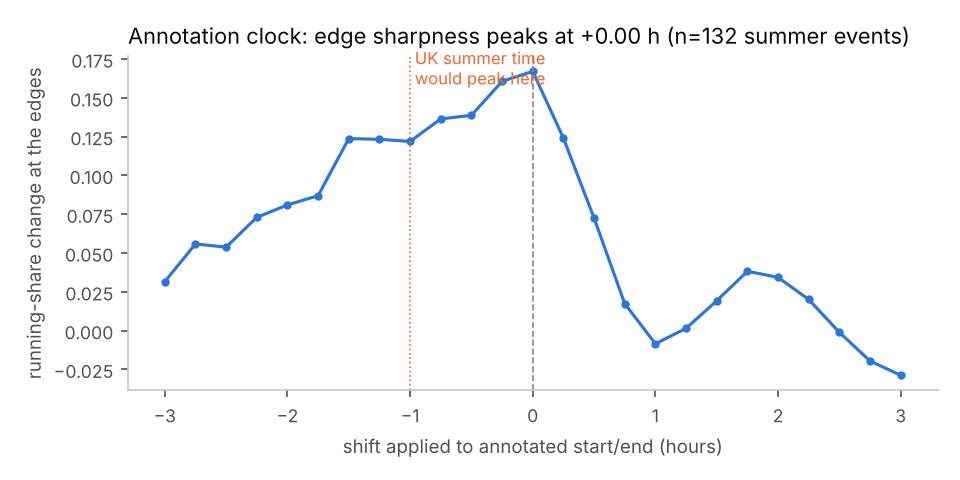

best shift: 0.0 h -> annotation times are UTC


In [3]:
display(Image(filename=str(FIG / "label_alignment.png"), width=620))
print("best shift:", q["alignment"]["best_shift_h"], "h ->", q["alignment"]["conclusion"])

## 3. EDA

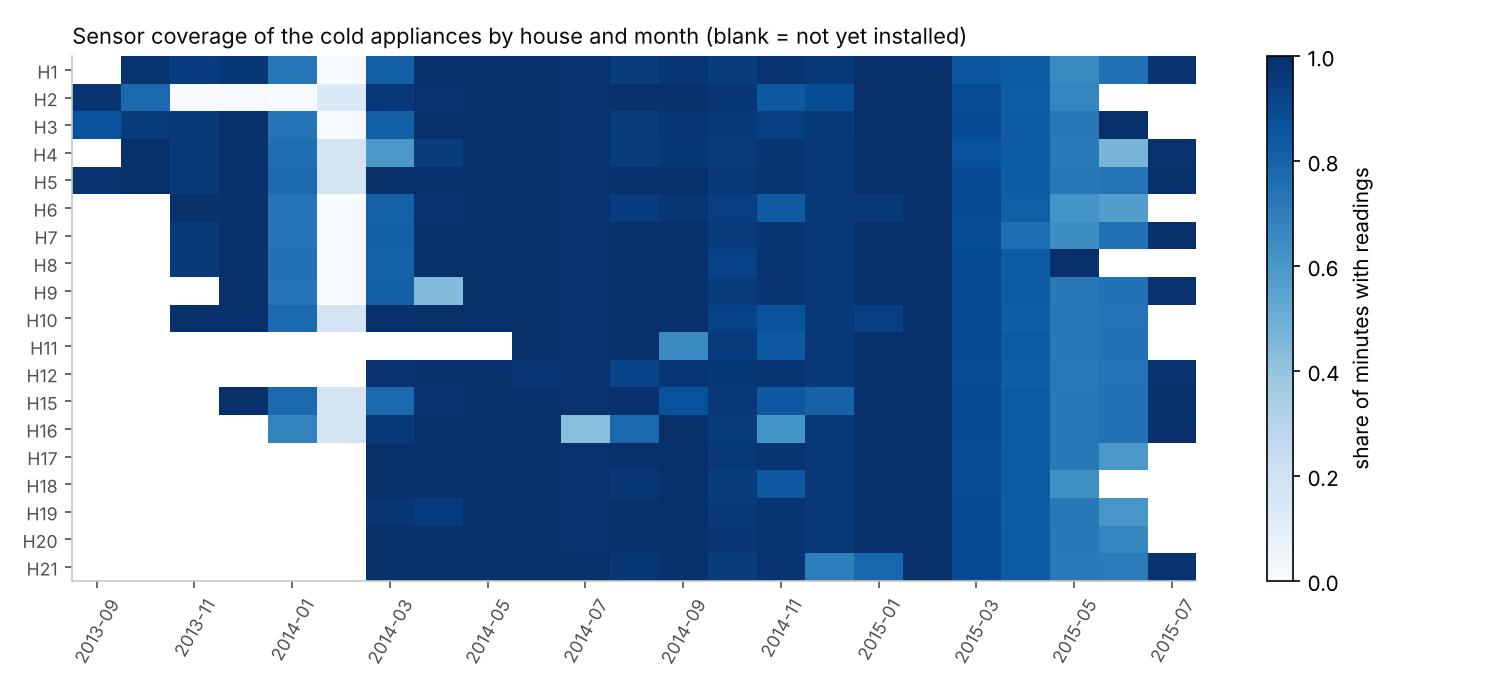

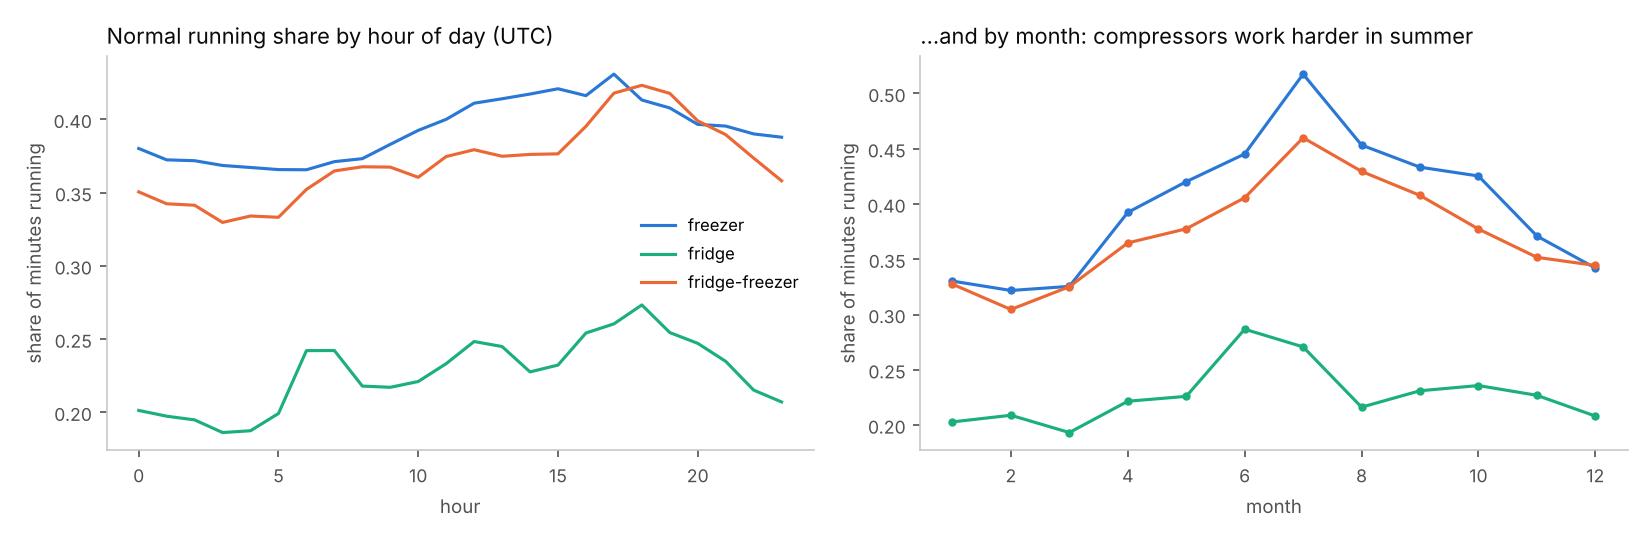

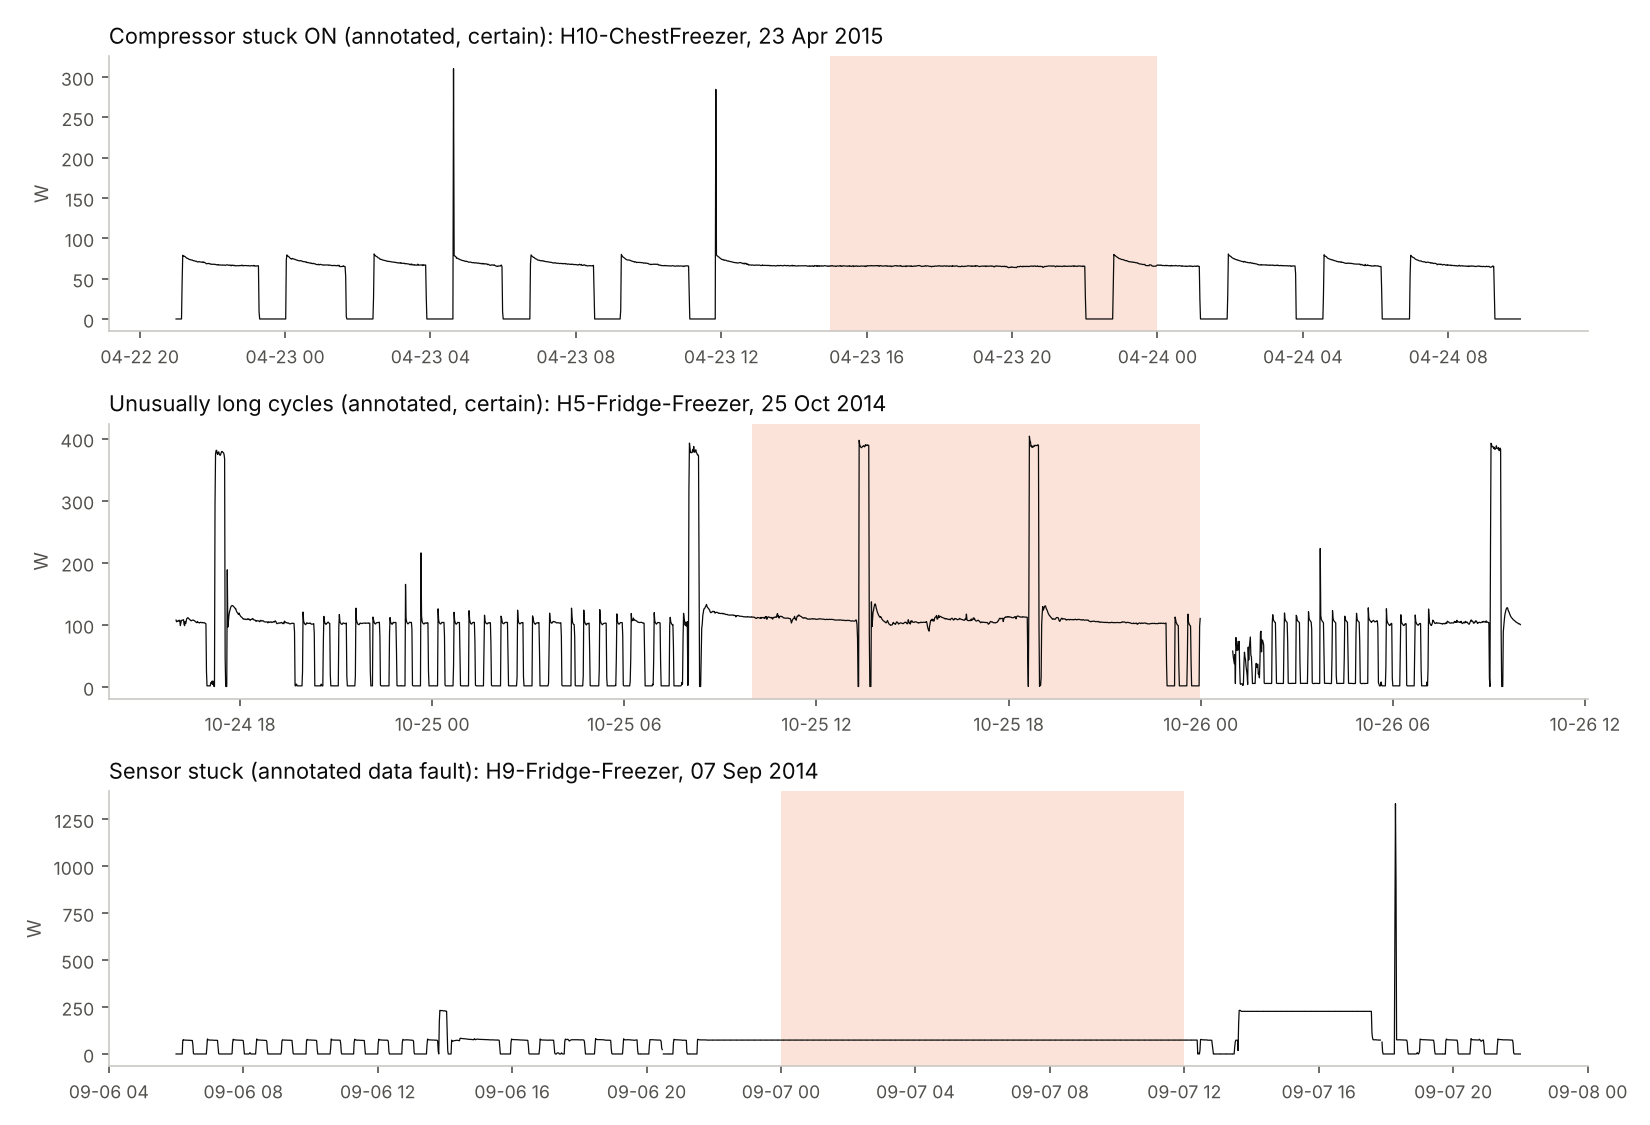

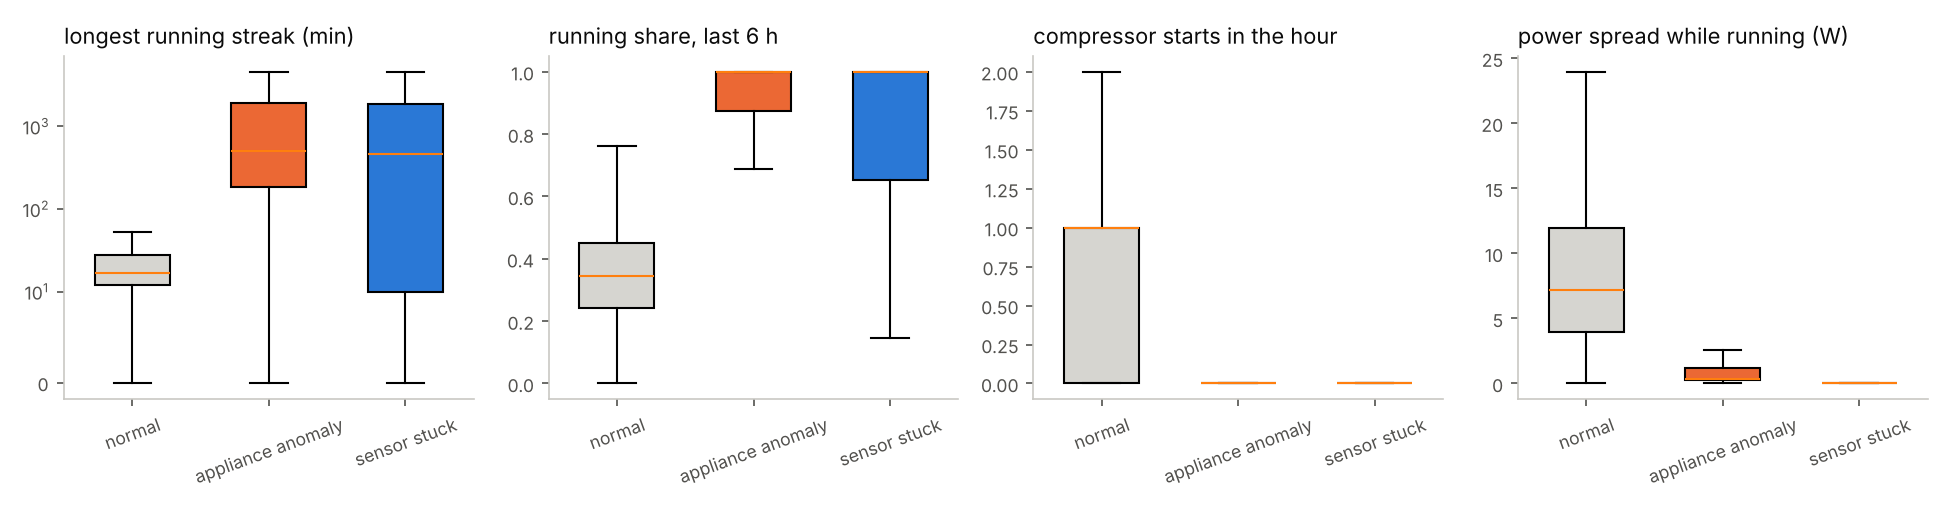

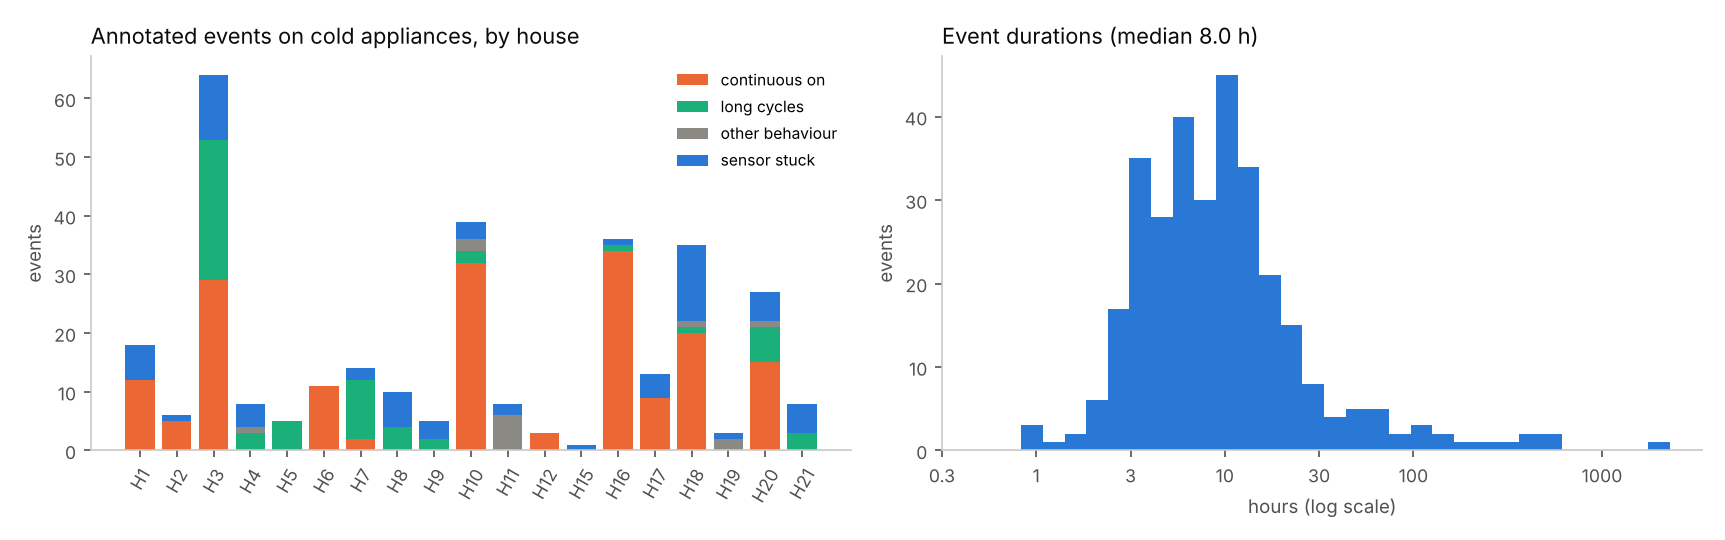

normal running share by type: {'freezer': 0.392, 'fridge': 0.227, 'fridge_freezer': 0.371}
hours with a 4 h+ running streak: 8,886; annotated: 66%
most unannotated 4 h+ hours: {'H21-Fridge-Freezer': 1774, 'H20-Freezer': 301, 'H3-Fridge-Freezer': 249, 'H19-FridgeFreezer': 149, 'H16-Fridge-Freezer_1': 145}


In [4]:
e = load("eda.json")
for f in ["eda_coverage.png", "eda_normal_behaviour.png", "eda_anomaly_examples.png", "eda_feature_separation.png", "eda_events.png"]:
    display(Image(filename=str(FIG / f), width=900))
print("normal running share by type:", e["duty_by_type"])
print(f"hours with a 4 h+ running streak: {e['hours_running_4h_plus']:,}; annotated: {e['share_of_those_annotated']:.0%}")
print("most unannotated 4 h+ hours:", e["unannotated_4h_runs_by_appliance_top"])

Labels are incomplete: a third of 4-hour running streaks are not annotated, mostly on one fridge-freezer (House 21).
Every 'false alert' rate in this project is therefore an upper bound and precision a lower bound.

## 4. Detectors on unseen homes (deployable thresholds)

,anomalies caught,recall,false / appliance-month,alerts on frozen sensors,median delay (h),PR-AUC (hour),ROC-AUC (hour)
detector,,,,,,,
Rule: compressor-on timer (run_max),190/243,0.782,1.178,15,3.0,0.573,0.956
Rule: on-timer vs own first month (run_ref),187/243,0.770,0.951,29,2.0,0.356,0.873
Isolation Forest (unsupervised),92/243,0.379,1.339,37,4.0,0.212,0.956
Logistic regression,180/243,0.741,1.004,19,3.0,0.291,0.898
Random forest,202/243,0.831,1.112,22,2.0,0.482,0.982
Extra trees,183/243,0.753,0.534,14,3.0,0.548,0.986
Gradient boosting (HGB),210/243,0.864,0.858,17,2.5,0.541,0.982


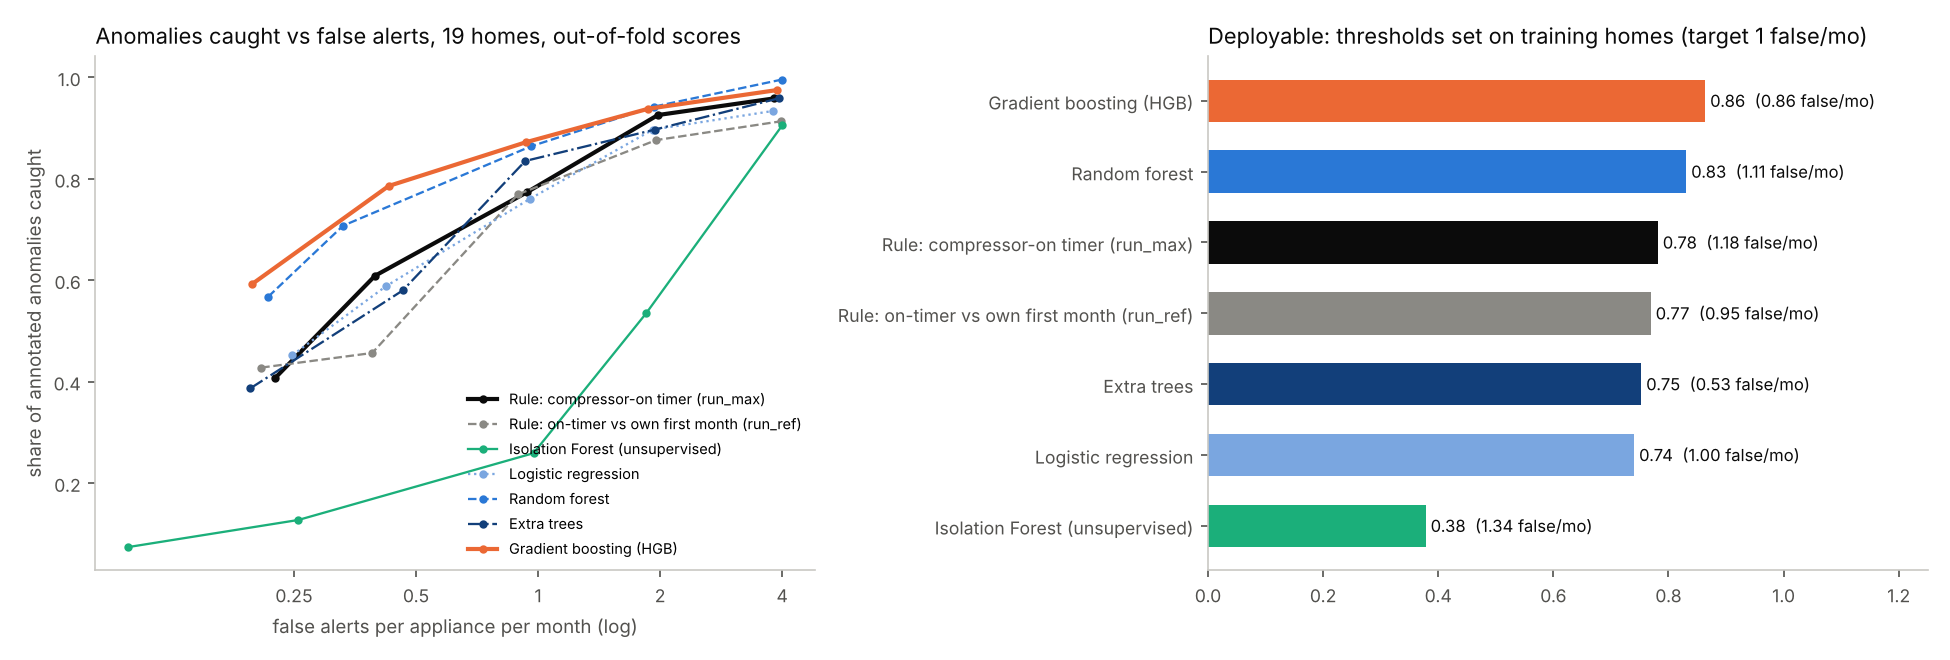

In [5]:
det = load("detection.json")
rows = []
for n, v in det.items():
    b = v["by_budget"]["1.0"]
    rows.append({"detector": n, "anomalies caught": f"{b['hit']}/{b['events']}", "recall": b["recall"], "false / appliance-month": b["false_per_app_month"],
                 "alerts on frozen sensors": b["stuck_alerts"], "median delay (h)": b["median_delay_h"], "PR-AUC (hour)": v["ap_hour"],
                 "ROC-AUC (hour)": v["roc_auc_hour"]})
display(pd.DataFrame(rows).set_index("detector").round(3))
display(Image(filename=str(FIG / "detection_comparison.png"), width=950))

## 5. Matched false-alert rate, ablation and hypothesis tests

In [6]:
m = load("matched.json")
display(pd.DataFrame({k: {**{f"recall @ {b}/mo": v["curve"][b]["recall"] for b in v["curve"]}, "95% CI @ 1/mo (homes)": f"{v['ci95'][0]:.2f}-{v['ci95'][1]:.2f}"}
                      for k, v in m.items()}).T.round(3))
h = load("hypotheses.json")
display(pd.DataFrame({k: {"claim": v["claim"], "p": v["p"], "p (Holm)": v["p_holm"], "supported": v["supported"]}
                      for k, v in h.items() if isinstance(v, dict)}).T)

,recall @ 0.25/mo,recall @ 0.5/mo,recall @ 1.0/mo,recall @ 2.0/mo,recall @ 4.0/mo,95% CI @ 1/mo (homes)
Rule: compressor-on timer (run_max),0.407407,0.609053,0.773663,0.925926,0.958848,0.64-0.88
Rule: on-timer vs own first month (run_ref),0.427984,0.45679,0.769547,0.876543,0.91358,0.58-0.92
Isolation Forest (unsupervised),0.074074,0.127572,0.259259,0.534979,0.90535,0.16-0.35
Logistic regression,0.452675,0.588477,0.761317,0.897119,0.934156,0.60-0.87
Random forest,0.567901,0.707819,0.864198,0.942387,0.995885,0.76-0.94
Extra trees,0.386831,0.580247,0.835391,0.897119,0.958848,0.74-0.92
Gradient boosting (HGB),0.592593,0.786008,0.872428,0.938272,0.975309,0.78-0.94
HGB - raw behaviour only,0.320988,0.613169,0.72428,0.82716,0.938272,0.52-0.85
HGB - raw + recent duty,0.580247,0.736626,0.814815,0.880658,0.958848,0.67-0.90
HGB - relative-to-own-history only,0.304527,0.460905,0.613169,0.777778,0.851852,0.41-0.79


,claim,p,p (Holm),supported
H1,Gradient boosting (HGB) catches a larger share of anomalies per house than the timer rule at the same false-alert rate (1 per appliance-month),0.074487,0.074487,False
H2,Gradient boosting (HGB) raises its alert earlier than the timer rule on anomalies both catch,0.000024,0.000072,True
H3,Adding features relative to the appliance's own history raises per-house recall over raw behaviour only,0.000676,0.001352,True
H4,Sensor-stuck events show lower power variation while 'running' than real stuck-on compressors,0.0,0.0,True
H5,Cold appliances run a larger share of the time in summer than in winter,0.000011,0.000045,True


## 6. Frozen sensors vs real anomalies

In [7]:
st = load("stuck_sensor.json")
print(json.dumps(st, indent=1))

{
 "fault_events_running": 238,
 "stuck_events_running": 60,
 "median_flat_frac": {
  "fault": 0.13333333333333333,
  "stuck": 1.0
 },
 "median_p_on_std": {
  "fault": 1.085131287574768,
  "stuck": 0.0
 },
 "event_auc_flat_frac": 0.9793067226890756,
 "rule_hours": 3181,
 "rule_precision_vs_stuck_labels": 0.6947500785916378,
 "rule_share_on_fault_labels": 0.07041810751336058,
 "stuck_events_caught": 59,
 "stuck_events_scoreable": 65,
 "fault_events_wrongly_flagged_as_stuck": 26,
 "unlabelled_rule_hours_by_appliance": {
  "H20-Freezer": 320,
  "H3-Freezer": 161,
  "H18-Fridge_garag": 77,
  "H8-Freezer": 52,
  "H16-Fridge-Freezer_1": 47,
  "H4-Freezer": 13
 }
}


## 7. Explainability

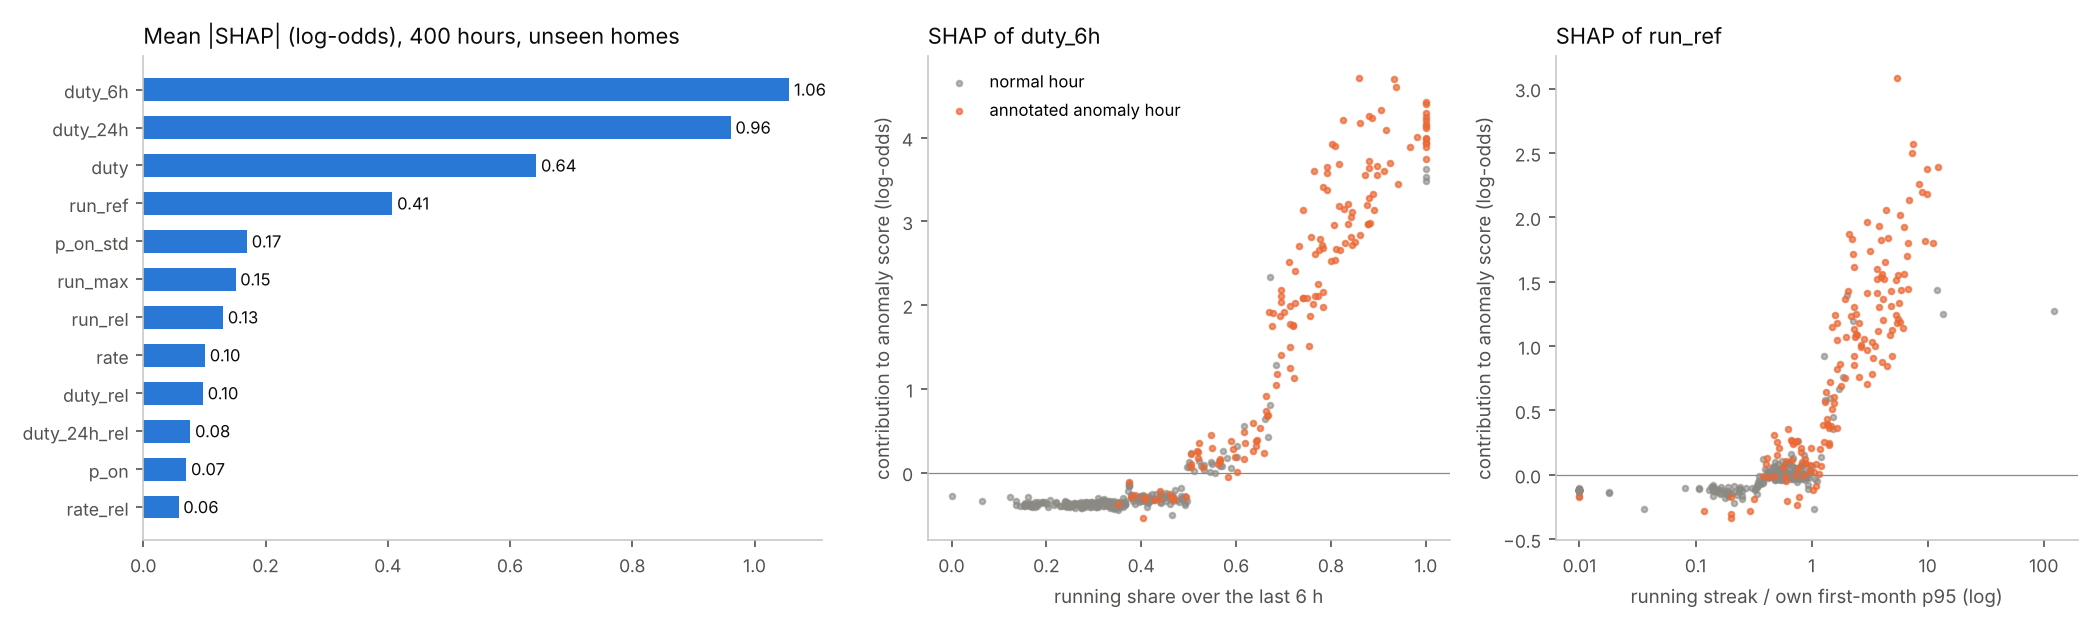

additivity check (max |base + sum(SHAP) - raw output|): 6.217248937900877e-15
example alert: {'appliance': 'H1-Freezer_2', 'hour_utc': '2015-03-25 23:00:00', 'fault_probability': 0.9969863449986325, 'top_contributions': {'duty_6h': 4.248, 'run_ref': 1.8, 'duty': 1.701, 'duty_24h': 1.21, 'p_on_std': 0.656, 'run_max': 0.624}, 'values': {'duty_6h': 1.0, 'run_ref': 11.094147582697214, 'duty': 1.0, 'duty_24h': 0.5708333333333333, 'p_on_std': 0.19942493736743927, 'run_max': 436.0}}


In [8]:
sh = load("shap.json")
display(Image(filename=str(FIG / "shap_hgb.png"), width=950))
print("additivity check (max |base + sum(SHAP) - raw output|):", sh["additivity_max_abs_error"])
print("example alert:", sh["example"])

## 8. Business impact

In [9]:
print(json.dumps(load("business.json"), indent=1))

{
 "events": 243,
 "fault_hours": 5958,
 "excess_kwh_median_event": 0.2475455284118652,
 "excess_kwh_total": 197.50756094615267,
 "excess_kwh_largest_event": 73.90968896974839,
 "price_gbp_per_kwh": 0.15,
 "response_time_h_assumed": 2,
 "cost_gbp_median_event": 0.03713182926177978,
 "cost_gbp_total": 29.626134141922897,
 "Rule: compressor-on timer (run_max)": {
  "events_caught": 190,
  "fault_hours_cut": 4841.916666666666,
  "share_of_fault_hours_cut": 0.8126748349558016,
  "kwh_avoidable": 153.8956689547155,
  "gbp_avoidable": 23.084350343207323,
  "false_alerts_per_appliance_year": 14.13292709466812,
  "alerts_on_frozen_sensors": 15
 },
 "Gradient boosting (HGB)": {
  "events_caught": 210,
  "fault_hours_cut": 4726.5,
  "share_of_fault_hours_cut": 0.7933031218529708,
  "kwh_avoidable": 153.7445965518492,
  "gbp_avoidable": 23.061689482777382,
  "false_alerts_per_appliance_year": 10.294668117519045,
  "alerts_on_frozen_sensors": 17
 }
}
